In [3]:
import pandas as pd
import numpy as np

# Walmart Weekly Sales Analysis and Predictive Modelling

## 1. Project Overview

This project explores Walmart's historical weekly sales data to understand sales patterns across stores, examine the relationship between sales and external factors, and develop a Linear Regression model to estimate weekly sales.

The analysis uses Python for data cleaning, exploratory data analysis, statistical evaluation, and predictive modelling.

## 2. Business Problem

Understanding weekly sales patterns is important for retail businesses to support better operational and business planning.

Variations in sales across stores, holiday periods, and external economic factors can make sales estimation challenging.

This project investigates the factors associated with Walmart's weekly sales and evaluates whether historical store-level and economic information can help explain sales variations.

## 3. Project Objectives

- Analyze weekly sales trends and variations across different stores.
- Examine the relationship between weekly sales and factors such as holidays, temperature, fuel prices, CPI, and unemployment.
- Identify patterns and potential relationships through exploratory data analysis.
- Develop and evaluate Linear Regression models to estimate weekly sales.
- Investigate regression assumptions and multicollinearity.
- Compare model performance and identify a suitable candidate for further validation.

In [5]:
data = pd.read_csv("Walmart_Sales.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Walmart_Sales.csv'

In [3]:
data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [4]:
data.shape

(6435, 8)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


## 4. Dataset Description

The dataset contains historical weekly sales information for 45 Walmart stores, along with holiday indicators and selected economic and environmental variables.

The dataset consists of 6,435 records and 8 original columns.

### Data Dictionary

| Column | Description |
|---|---|
| Store | Unique identifier for each Walmart store |
| Date | Week-ending date of the sales record |
| Weekly_Sales | Total sales recorded by a store for that week |
| Holiday_Flag | Indicates whether the week includes a holiday (1 = Yes, 0 = No) |
| Temperature | Temperature recorded for the week |
| Fuel_Price | Fuel price during the corresponding week |
| CPI | Consumer Price Index |
| Unemployment | Unemployment rate |

### Dataset Characteristics

- Number of records: 6,435
- Number of stores: 45
- Records per store: 143
- Original features: 8
- Target variable: Weekly_Sales

In [6]:
#Converting Date column in to date type

In [7]:
data['Date'] = pd.to_datetime(data['Date'], format = '%d-%m-%Y')

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


In [9]:
# Checking duplicate values
data.duplicated().sum()

np.int64(0)

In [10]:
#Missing Values
data.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

#Creating year, month and day column from the existing Date colums for analysis

In [11]:
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day

In [12]:
data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,12
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,19
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,26
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,5


## 5. Data Cleaning and Preparation

Before performing exploratory data analysis, the dataset was inspected to understand its structure, identify data quality issues, and prepare the variables for analysis.

The following checks and preparation steps were performed:

- Inspected the dataset dimensions, column names, and data types.
- Checked for missing values across all columns.
- Checked for duplicate records.
- Converted the Date column into a datetime format.
- Extracted additional time-based features such as Year, Month, and Day for exploratory analysis.
- Reviewed the distribution of the target variable, Weekly_Sales, to understand its characteristics.

### Data Quality Observations

- The dataset contains 6,435 records across 45 stores.
- No missing values were identified.
- No duplicate records were identified.
- Each store contains 143 weekly observations.

The dataset was considered suitable for further exploratory analysis based on these initial data quality checks.

## EDA

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

### Univariate Analysis

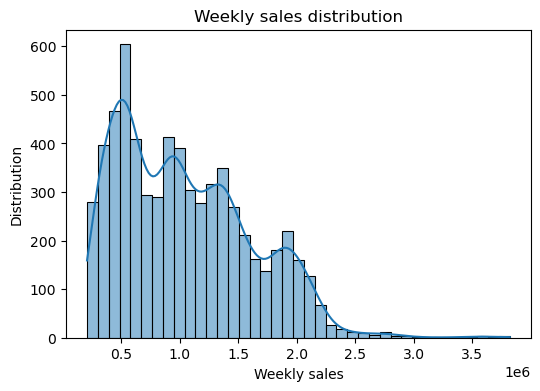

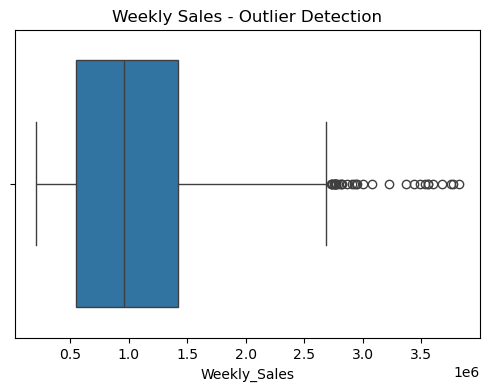

In [14]:
plt.figure(figsize=(6,4))
sns.histplot(data, x = 'Weekly_Sales', kde = True)
plt.title("Weekly sales distribution")
plt.xlabel("Weekly sales")
plt.ylabel("Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'Weekly_Sales')
plt.title('Weekly Sales - Outlier Detection')
plt.show()


Observations – Weekly Sales Distribution

1. The Weekly_Sales distribution is positively skewed (right-skewed), indicating that most observations are concentrated at relatively lower sales values, with a smaller number of observations having significantly higher sales.

2. The boxplot identifies several potential outliers on the upper side of the distribution.

3. The presence of these extreme values may be influenced by differences in store-level sales performance or specific high-demand periods.

Further Investigation:
Investigate the potential outliers by comparing store-level sales and holiday periods before deciding whether any data cleaning is required.

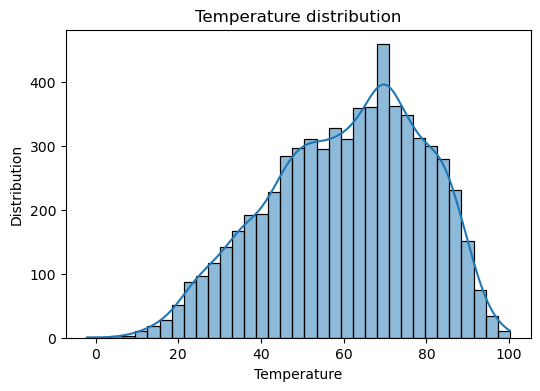

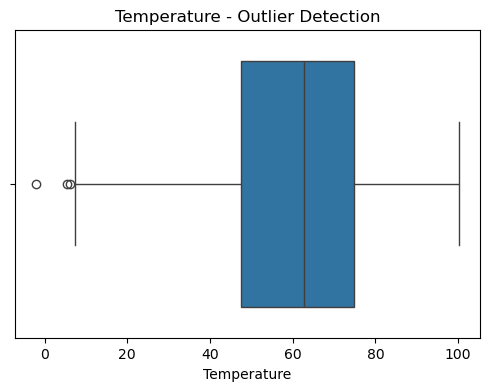

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(data, x = 'Temperature', kde = True)
plt.title("Temperature distribution")
plt.xlabel("Temperature")
plt.ylabel("Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'Temperature')
plt.title('Temperature - Outlier Detection')
plt.show()


Observations: Temperature Analysis

1. Distribution: Roughly bell-shaped and centered between 65°F and 70°F, capturing a full seasonal range from ~0°F to 100°F.

2. Outliers: A few low-temperature points (0°F to 10°F) appear as outliers in the boxplot.

Decision: Retained in the dataset as genuine winter weather weeks so the model can learn how extreme cold affects retail sales.

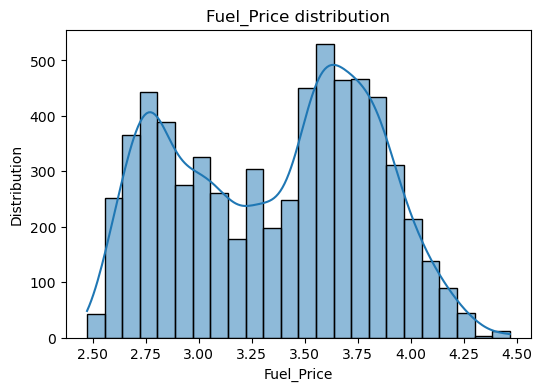

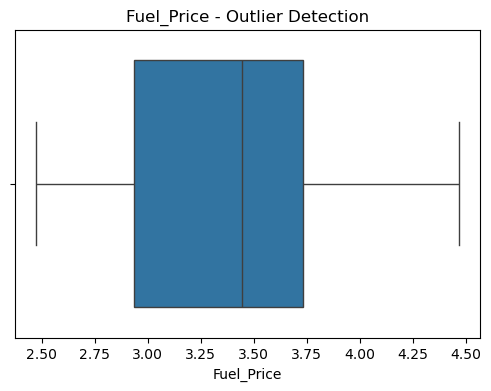

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(data, x = 'Fuel_Price', kde = True)
plt.title("Fuel_Price distribution")
plt.xlabel("Fuel_Price")
plt.ylabel("Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'Fuel_Price')
plt.title('Fuel_Price - Outlier Detection')
plt.show()

Observations: Fuel Price Analysis

1. Distribution: Shows a distinct bimodal pattern with two major peaks (around $2.75 and $3.60), reflecting changing economic and market cycles over time.

2. Range & Outliers: Prices range from roughly $2.50 to $4.50 with no statistical outliers detected in the boxplot.

Decision: Retained as-is since the distribution represents genuine market fluctuations.

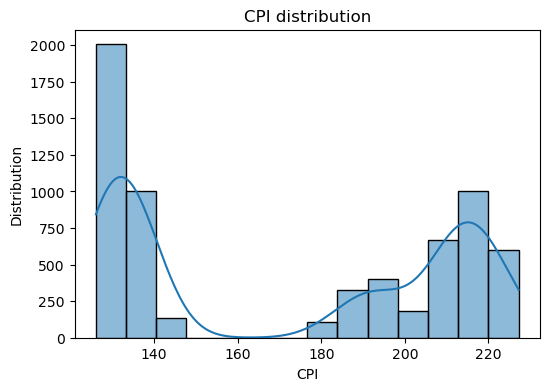

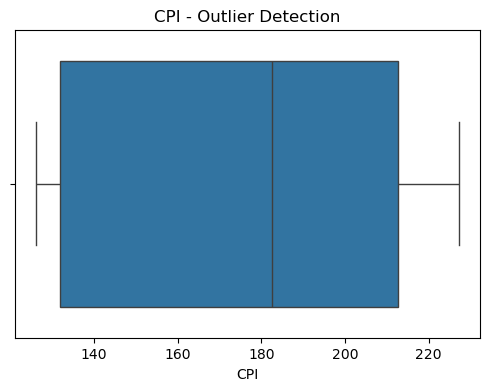

In [17]:
plt.figure(figsize=(6,4))
sns.histplot(data, x = 'CPI', kde = True)
plt.title("CPI distribution")
plt.xlabel("CPI")
plt.ylabel("Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'CPI')
plt.title('CPI - Outlier Detection')
plt.show()

Observations: CPI (Consumer Price Index) Analysis

1. Distribution: Features a distinct split distribution with two major groupings (around 130–140 and 180–220) and a deep trough in between, representing different macroeconomic phases in the dataset.

2. Outliers: The boxplot confirms no statistical outliers are present.

Decision: Retained in the raw EDA, but its high collinearity with temporal trends will be accounted for during feature selection.

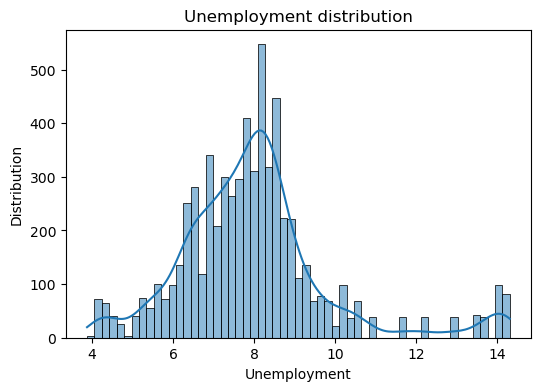

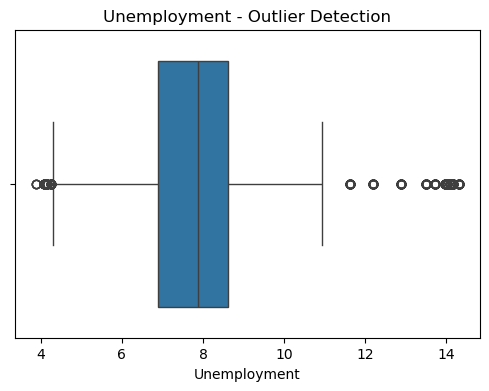

In [18]:
plt.figure(figsize=(6,4))
sns.histplot(data, x = 'Unemployment', kde = True)
plt.title("Unemployment distribution")
plt.xlabel("Unemployment")
plt.ylabel("Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'Unemployment')
plt.title('Unemployment - Outlier Detection')
plt.show()

Observations: Unemployment Analysis

1. Distribution: Primarily clustered around a median of 7% to 8.5%, showing a right-skewed tail extending toward higher unemployment rates.
2. Outliers: The boxplot identifies a cluster of high-unemployment values (ranging from ~11% to 14.5%) as statistical outliers.

Decision: Retained as valid macroeconomic economic data points (reflecting specific high-unemployment periods or regional economic downturns) rather than dropped.

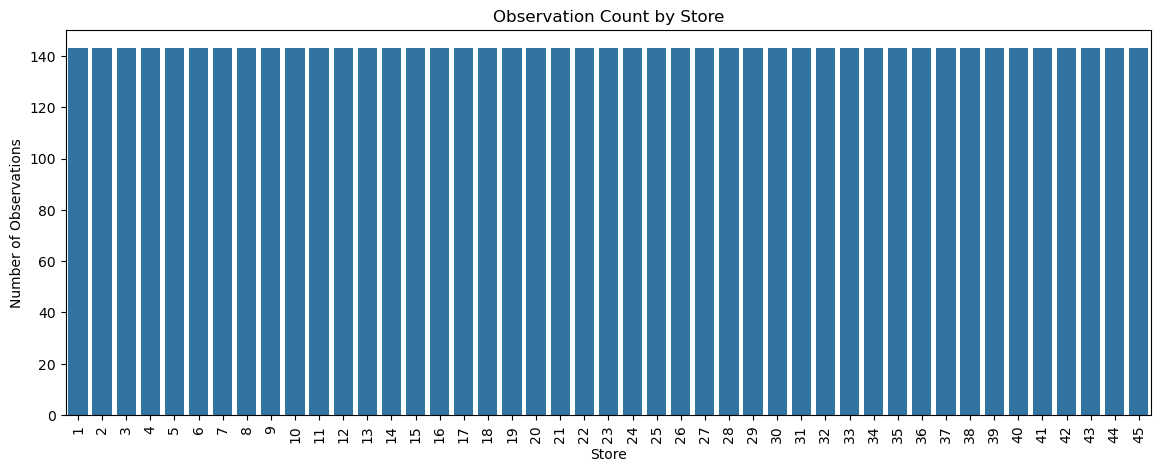

In [19]:
plt.figure(figsize=(14,5))
sns.countplot(data = data, x = 'Store')
plt.title('Observation Count by Store')
plt.xlabel('Store')
plt.ylabel('Number of Observations')
plt.xticks(rotation=90)
plt.show()

In [20]:
data['Store'].value_counts().describe()

count     45.0
mean     143.0
std        0.0
min      143.0
25%      143.0
50%      143.0
75%      143.0
max      143.0
Name: count, dtype: float64

In [21]:
data.groupby('Store').size().nunique()

1

Store Distribution – Key Observations

1. The dataset contains 45 unique stores.

2. Each store has 143 observations.

3. The observation count is consistent across all stores, indicating balanced record coverage.

Conclusion: No store-level observation imbalance was identified. Therefore, no additional investigation into record counts is required at this stage.

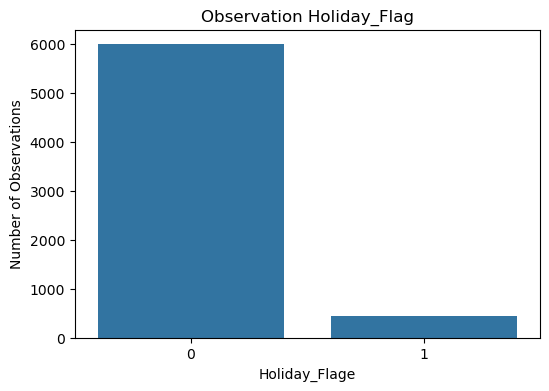

In [22]:
plt.figure(figsize=(6,4))
sns.countplot(data = data, x = 'Holiday_Flag')
plt.title('Observation Holiday_Flag')
plt.xlabel('Holiday_Flage')
plt.ylabel('Number of Observations')
plt.show()

Holiday_Flag – Key Observations

1. Approximately 93% of observations represent non-holiday weeks.

2. Approximately 7% of observations represent holiday weeks.

3. The dataset contains considerably fewer holiday observations than non-holiday observations.

Conclusion: Holiday observations are relatively limited compared with non-holiday observations. The impact of holidays on weekly sales will be investigated during bivariate analysis.

### Bivariate Analysis

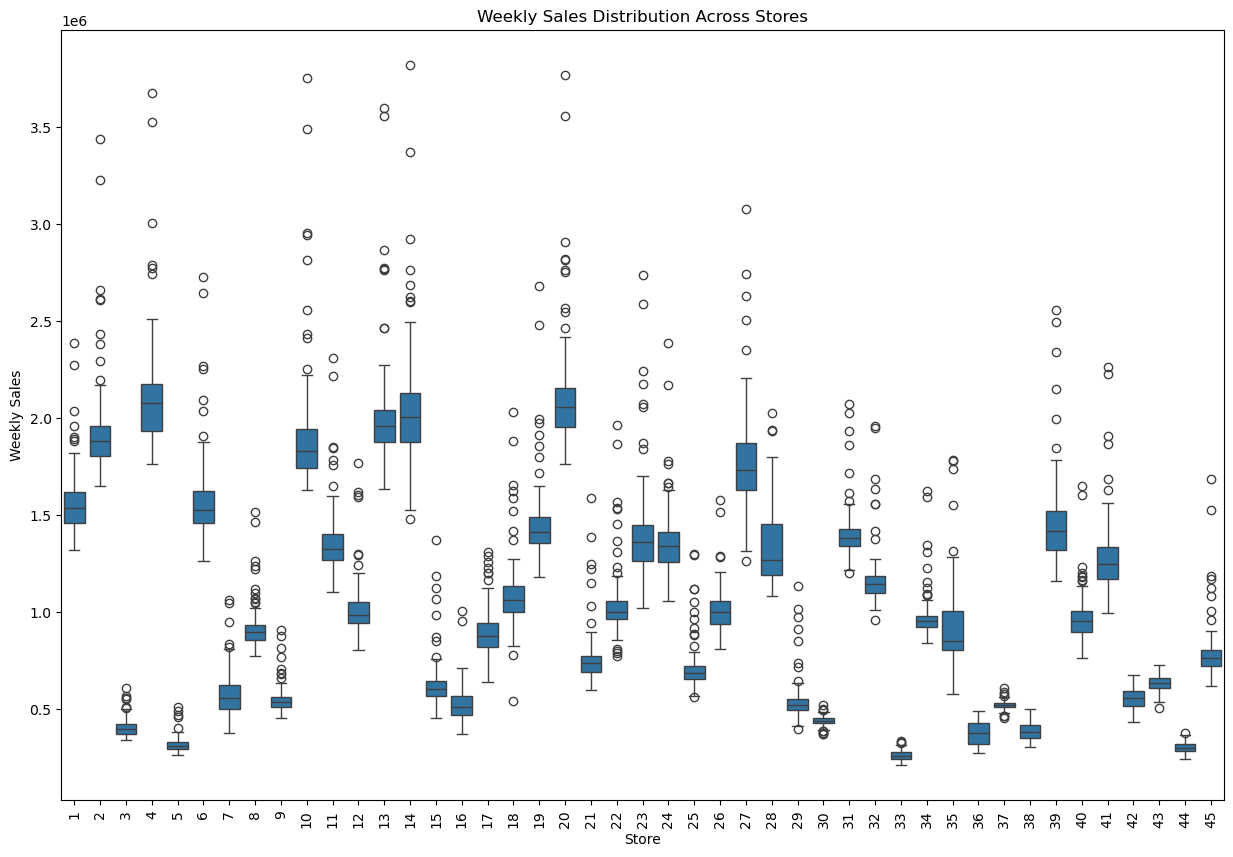

In [23]:
plt.figure(figsize=(15,10))
sns.boxplot(data, x = 'Store', y = 'Weekly_Sales')
plt.title('Weekly Sales Distribution Across Stores')
plt.xlabel('Store')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=90)
plt.show()

Store vs Weekly_Sales

1. Store-Level Variability: There is massive variance in sales performance across different stores. Some locations (e.g., Stores 4, 14, 20) consistently generate high median sales volumes ($> \$2M$), while others (e.g., Stores 33, 36, 44) stay consistently low ($< \$0.5M$).

2. Outliers: Several stores show upper-bound sales outliers, typically driven by major holiday spikes (like Thanksgiving or Christmas weeks).

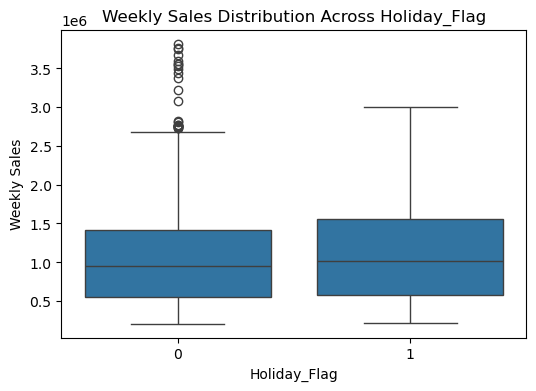

In [24]:
plt.figure(figsize=(6,4))
sns.boxplot(data, x = 'Holiday_Flag', y = 'Weekly_Sales')
plt.title('Weekly Sales Distribution Across Holiday_Flag')
plt.xlabel('Holiday_Flag')
plt.ylabel('Weekly Sales')
plt.show()

Observations: Holiday Impact on Weekly Sales

1. Distribution Shift: Holiday weeks (1) show a slightly higher median and upper quartile range compared to standard non-holiday weeks (0).

2. Outliers: Non-holiday weeks (0) display numerous upper-bound sales outliers, capturing exceptional retail spikes outside of officially designated holidays.


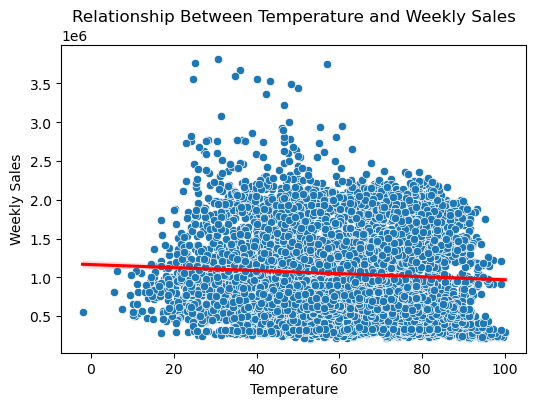

In [25]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x = 'Temperature', y = 'Weekly_Sales')
sns.regplot(data, x='Temperature', y='Weekly_Sales', scatter=False, color = 'red')
plt.title('Relationship Between Temperature and Weekly Sales')
plt.xlabel('Temperature')
plt.ylabel('Weekly Sales')
plt.show()

Observations: Temperature vs. Weekly Sales

1. Spread: Data points are heavily concentrated across mild temperatures (40°F to 80°F), with highest sales peaks occurring in the moderate-to-cool range.

2. Trend: The regression line will help illustrate the linear relationship (or lack thereof) between temperature fluctuations and sales volume.

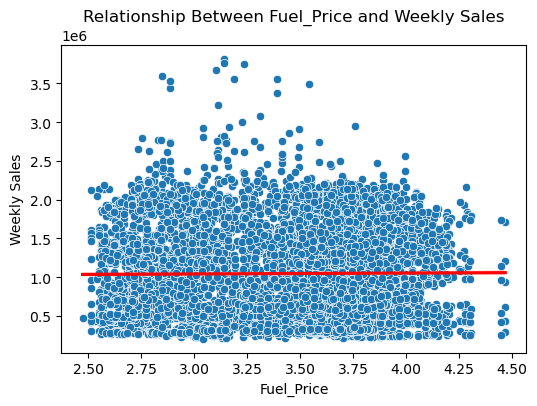

In [26]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x = 'Fuel_Price', y = 'Weekly_Sales')
sns.regplot(data, x='Fuel_Price', y='Weekly_Sales', scatter=False, color = 'red')
plt.title('Relationship Between Fuel_Price and Weekly Sales')
plt.xlabel('Fuel_Price')
plt.ylabel('Weekly Sales')
plt.show()

Observations: Fuel Price vs. Weekly Sales

1. Trend & Relationship: The flat red regression line indicates virtually no linear relationship between fuel prices and weekly sales volumes. Changes in gas prices do not directly drive or restrict store revenue on a macro level.

2. Spread: Data points are distributed evenly across the entire fuel price range ($\$2.50$ to $\$4.50$) for all sales tiers.

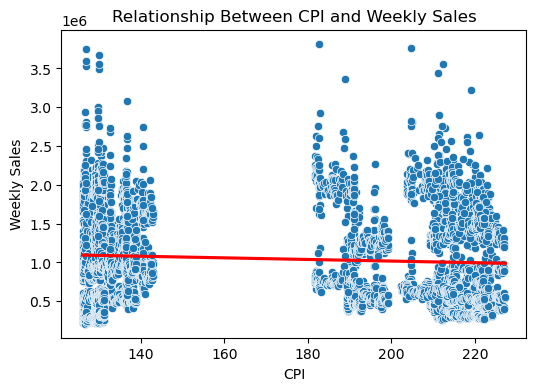

In [27]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x = 'CPI', y = 'Weekly_Sales')
sns.regplot(data, x='CPI', y='Weekly_Sales', scatter=False, color = 'red')
plt.title('Relationship Between CPI and Weekly Sales')
plt.xlabel('CPI')
plt.ylabel('Weekly Sales')
plt.show()

Observations: CPI vs. Weekly Sales

1. Trend & Relationship: The red regression line shows a slight negative slope, indicating minimal to no direct linear correlation between the Consumer Price Index and weekly sales volumes.

2. Clustering: Data points clearly reflect the bimodal distribution of CPI, forming distinct vertical groupings around the 130–140 range and the 180–220 range.

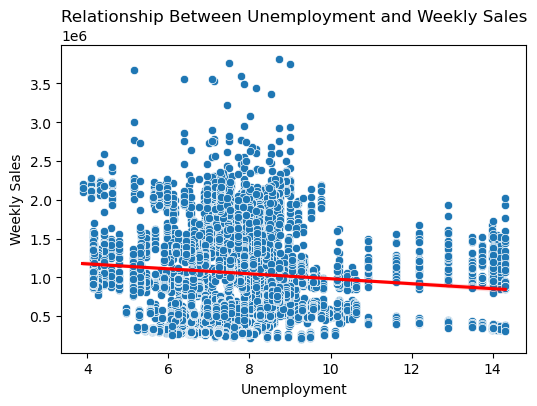

In [28]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x = 'Unemployment', y = 'Weekly_Sales')
sns.regplot(data, x='Unemployment', y='Weekly_Sales', scatter=False, color = 'red')
plt.title('Relationship Between Unemployment and Weekly Sales')
plt.xlabel('Unemployment')
plt.ylabel('Weekly Sales')
plt.show()

Observations: Unemployment vs. Weekly Sales

1. Trend & Relationship: The red regression line shows a slight downward slope, indicating a weak negative relationship where higher unemployment rates tend to correspond with marginally lower sales volumes.

2. Concentration: The majority of data points are densely packed between 6% and 10% unemployment, with sparser points stretching out toward the high-unemployment outliers near 14%.

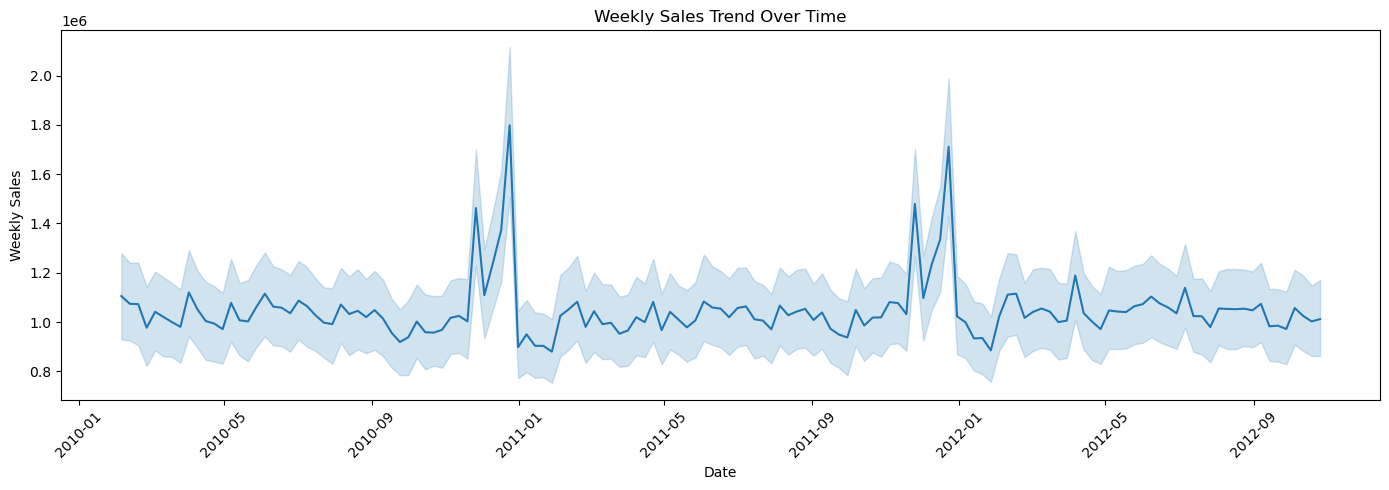

In [29]:
data_sorted = data.sort_values('Date')

plt.figure(figsize=(14,5))

sns.lineplot(
    data=data_sorted,
    x='Date',
    y='Weekly_Sales'
)

plt.title('Weekly Sales Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observations: Weekly Sales Trend Over Time

1. Temporal Trends & Seasonality: The line plot reveals a stable baseline sales trend throughout most of the year, punctuated by dramatic, sharp sales spikes peaking in November/December of each year (driven by major holiday shopping seasons).

2. Confidence Interval: The shaded band represents the variance/spread across all stores over time.

### Multivariate Analysis

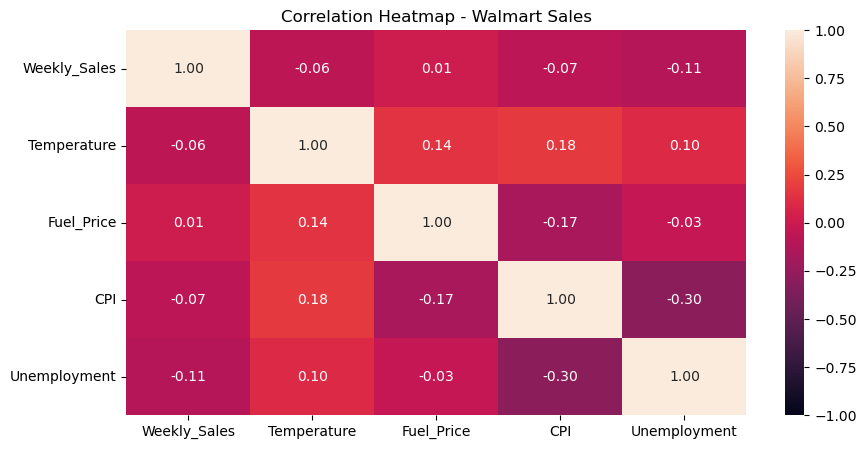

In [30]:
num_var = data[['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']]
corr_matrix = num_var.corr()
plt.figure(figsize=(10,5))
sns.heatmap(corr_matrix, annot=True, vmin = -1, vmax = 1, fmt='.2f')
plt.title('Correlation Heatmap - Walmart Sales')
plt.show()
           

Observations: Correlation Heatmap Analysis

1. Target Correlation: Weekly_Sales exhibits very weak linear correlation coefficients with all numerical features (ranging from -0.11 for Unemployment to 0.01 for Fuel_Price), confirming that standalone macroeconomic variables have minimal direct linear impact on sales.

2. Multicollinearity Indicators: Moderate associations appear between macroeconomic factors (such as -0.30 between CPI and Unemployment), reinforcing the need to monitor multicollinearity via VIF.



<Figure size 1000x600 with 0 Axes>

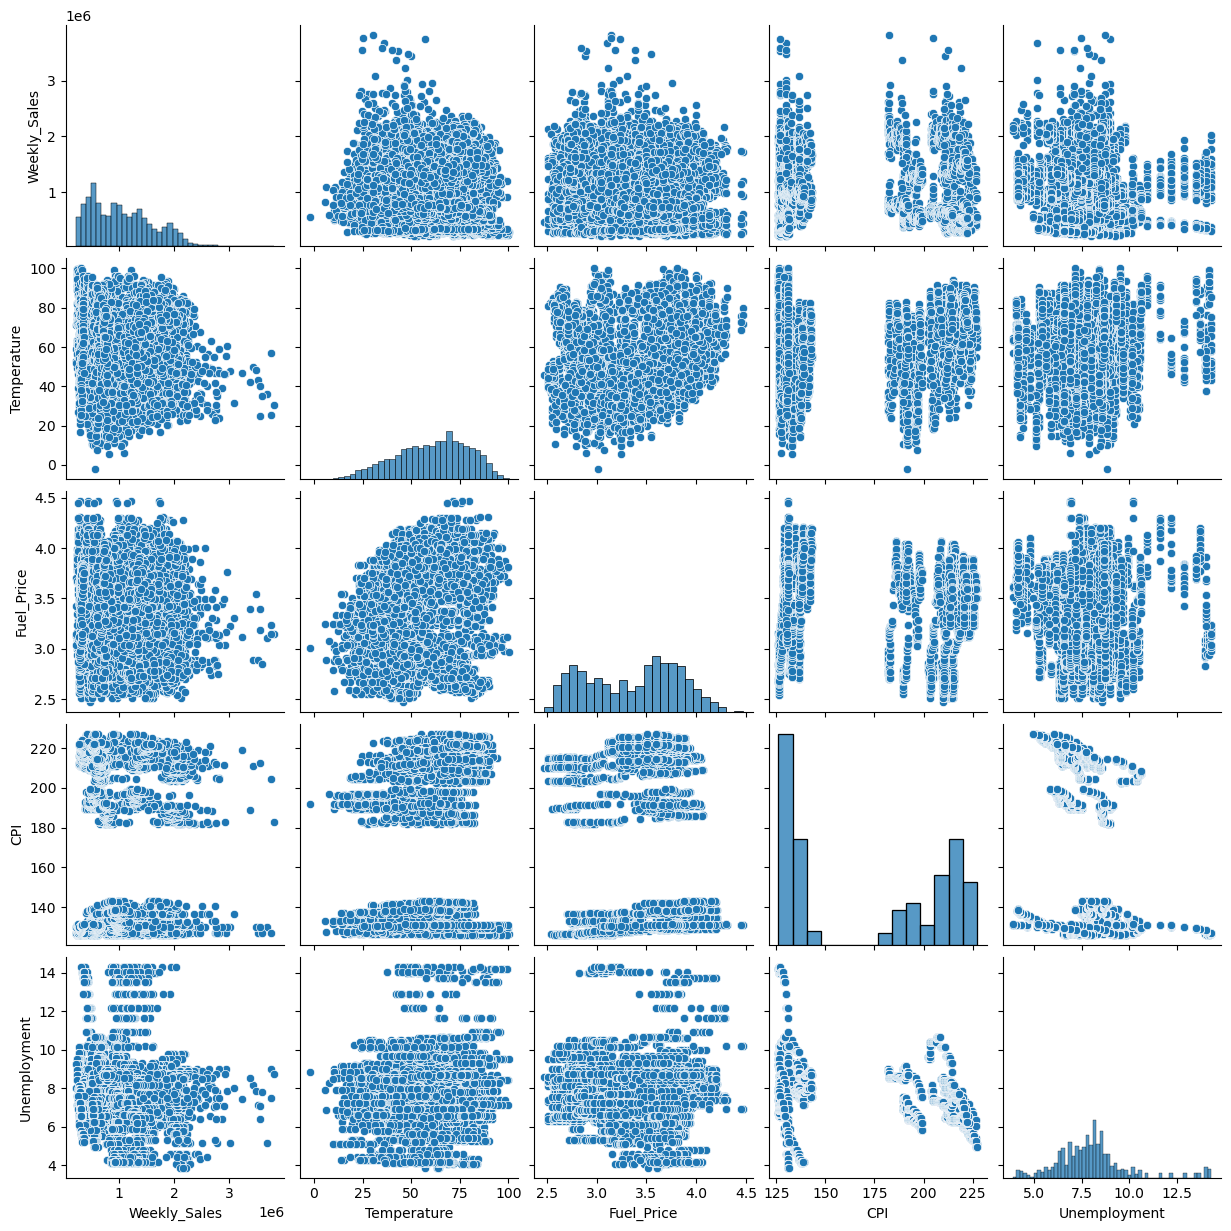

In [31]:
plt.figure(figsize=(10,6))
sns.pairplot(num_var)
plt.show()

Observations: Pairplot Matrix Summary

1. Holistic View: Combines univariate histograms along the diagonal with bivariate scatter plots across all numeric features (Weekly_Sales, Temperature, Fuel_Price, CPI, and Unemployment).

2. Multi-Variable Patterns: Clearly displays the complex structural groupings (such as the bimodal splits in CPI and Fuel_Price) and highlights how each predictor interacts across the entire multi-dimensional space.

## Model Development

In this section, we develop a Linear Regression model to understand the relationship between weekly sales and the available business and economic variables.

The target variable is Weekly_Sales. The independent variables include Store, Holiday_Flag, Temperature, Fuel_Price, CPI and Unemployment.

The Date column and its derived features are excluded from this baseline model.

In [32]:
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

In [33]:
df = data.copy()

In [34]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,12
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,19
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,26
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,5


In [35]:
x = df.drop(['Weekly_Sales', 'Date', 'Year', 'Month', 'Day'], axis =1)
y = df['Weekly_Sales']

In [36]:
x = pd.get_dummies(x, columns=['Store'], drop_first = True)

In [37]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 49 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Holiday_Flag  6435 non-null   int64  
 1   Temperature   6435 non-null   float64
 2   Fuel_Price    6435 non-null   float64
 3   CPI           6435 non-null   float64
 4   Unemployment  6435 non-null   float64
 5   Store_2       6435 non-null   bool   
 6   Store_3       6435 non-null   bool   
 7   Store_4       6435 non-null   bool   
 8   Store_5       6435 non-null   bool   
 9   Store_6       6435 non-null   bool   
 10  Store_7       6435 non-null   bool   
 11  Store_8       6435 non-null   bool   
 12  Store_9       6435 non-null   bool   
 13  Store_10      6435 non-null   bool   
 14  Store_11      6435 non-null   bool   
 15  Store_12      6435 non-null   bool   
 16  Store_13      6435 non-null   bool   
 17  Store_14      6435 non-null   bool   
 18  Store_15      6435 non-null 

In [38]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state =1)

In [39]:
x_train_sm = sm.add_constant(x_train.astype(float))
x_test_sm = sm.add_constant(x_test.astype(float))

In [40]:
base_model = sm.OLS(y_train, x_train_sm).fit()
print(base_model.summary())

                            OLS Regression Results                            
Dep. Variable:           Weekly_Sales   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     1049.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:32:34   Log-Likelihood:                -60332.
No. Observations:                4504   AIC:                         1.208e+05
Df Residuals:                    4454   BIC:                         1.211e+05
Df Model:                          49                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.068e+06   2.71e+05      3.946   

In [41]:
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error

In [42]:
y_pred = base_model.predict(x_test_sm)
y_pred_train = base_model.predict(x_train_sm)

In [43]:
print('Train R2:', r2_score(y_train, y_pred_train))
print('Train MAE:', mean_absolute_error(y_train, y_pred_train))
print('Train MSE:', mean_squared_error(y_train, y_pred_train))

print('Test R2:', r2_score(y_test, y_pred))
print('Test MAE:', mean_absolute_error(y_test, y_pred))
print('Test MSE:', mean_squared_error(y_test, y_pred))

Train R2: 0.9202835462390404
Train MAE: 91678.97401255433
Train MSE: 25264738539.29058
Test R2: 0.9188207408459161
Test MAE: 91581.27258682229
Test MSE: 26138847584.150448


Key Observations
- The model explains approximately 92% of the variation in weekly sales in both datasets.
- Training and testing performance are very similar.
- There is no obvious evidence of overfitting based on these results.

## Regression Assumption Testing

After developing the baseline Multiple Linear Regression model, we evaluated the key regression assumptions to assess the reliability of the model and identify potential limitations.

The following assumptions were examined:

### 1. Linearity
**Method:** Residuals vs Fitted Values plot.

The plot was used to assess whether the residuals were randomly distributed around zero or displayed a systematic pattern.

### 2. Normality of Residuals
**Method:** Histogram and Q-Q plot.

These visualizations were used to assess whether the residuals approximately followed a normal distribution.

### 3. Multicollinearity
**Method:** Variance Inflation Factor (VIF).

VIF was calculated to identify potential multicollinearity among the independent variables. Higher VIF values may indicate that predictors are strongly related to one another.

### 4. Homoscedasticity
**Method:** Breusch–Pagan test.

The test was used to examine whether the residual variance remained constant across fitted values.

### 5. Independence of Residuals
**Method:** Durbin–Watson test.

The test was used to assess first-order autocorrelation in the residuals. Since the dataset contains weekly observations across multiple stores, chronological ordering must be preserved when evaluating temporal independence.

### Overall Assessment

The assumption tests help identify potential limitations in the Linear Regression model. Their findings will be considered when interpreting model coefficients, statistical significance, and predictive performance.

In [44]:
#1. Linearity

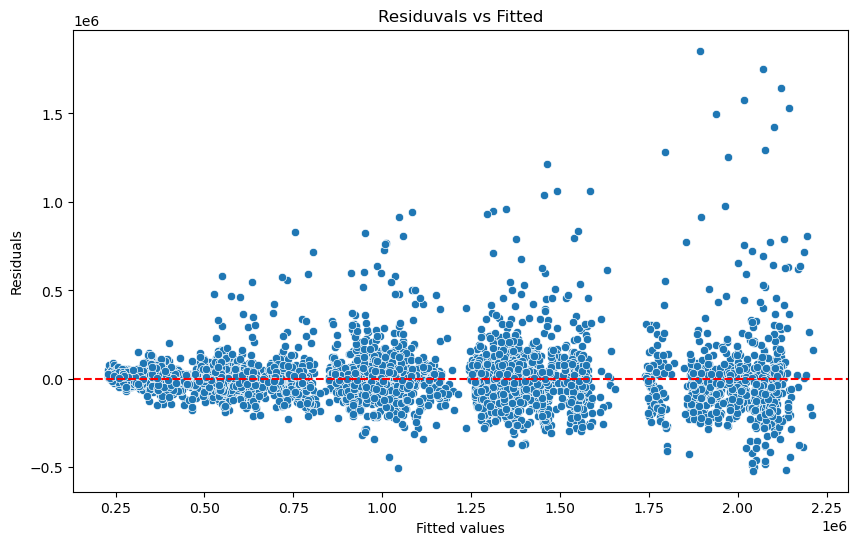

In [45]:
residuals = base_model.resid
fitted_val = base_model.fittedvalues

plt.figure(figsize=(10,6))
sns.scatterplot(x= fitted_val, y = residuals)
plt.axhline(y = 0, color = 'red', linestyle = '--')
plt.title('Residuvals vs Fitted')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()
          


#### Linearity – Residuals vs Fitted Values

Observations:

Residuals are generally distributed around the zero reference line.

No clearly defined curved pattern is observed.

The spread of residuals increases at higher fitted values.

Several large positive residuals are present.

Conclusion:

There is no obvious indication of a strong nonlinear relationship from the residual plot. However, the increasing spread of residuals suggests potential heteroscedasticity, which requires further investigation.

In [46]:
#2.Normality

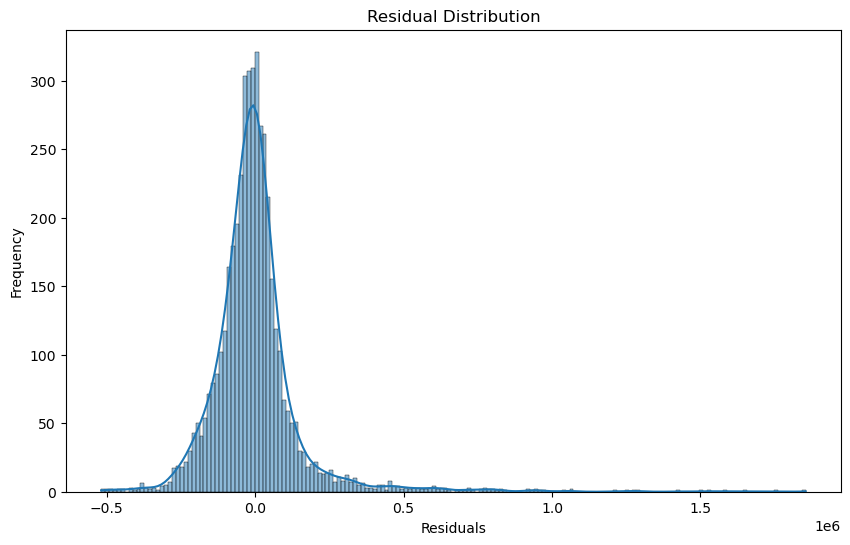

In [47]:
plt.figure(figsize=(10,6))
sns.histplot(data = residuals, kde = True)
plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

<Figure size 1000x600 with 0 Axes>

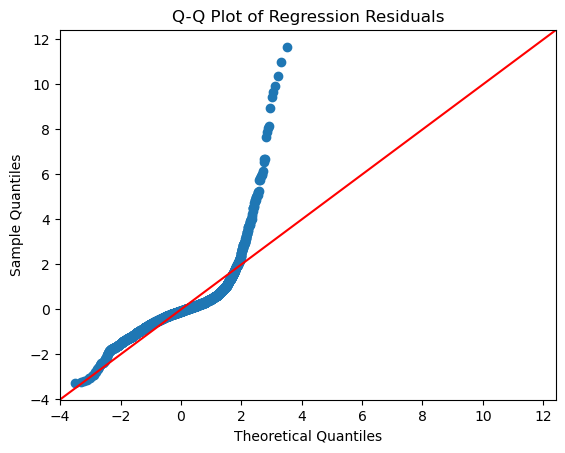

In [48]:
plt.figure(figsize=(10,6))
sm.qqplot(data = residuals, line ='45', fit = True)
plt.title('Q-Q Plot of Regression Residuals')
plt.show()

#### Normality of Residuals

Observations:

The residual distribution is positively skewed.

Most residuals are concentrated around zero, with a long positive tail.

The Q-Q plot shows substantial deviation from the reference line, particularly in the upper tail.

Conclusion:

The residuals do not appear to follow a normal distribution. This indicates that the normality assumption is not satisfied.

In [49]:
#3.Multicolinearity

In [50]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [51]:

# Create a DataFrame for VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = base_model.model.exog_names
vif_data["VIF"] = [
    variance_inflation_factor(base_model.model.exog, i)
    for i in range(base_model.model.exog.shape[1])
]
print(vif_data)

         Feature           VIF
0          const  12919.896323
1   Holiday_Flag      1.041078
2    Temperature      1.464013
3     Fuel_Price      2.725403
4            CPI    414.689758
5   Unemployment     16.358553
6        Store_2      1.945979
7        Store_3      2.081781
8        Store_4     51.543102
9        Store_5      2.039264
10       Store_6      2.079564
11       Store_7      4.675858
12       Store_8      2.169249
13       Store_9      2.119531
14      Store_10     43.185181
15      Store_11      2.062790
16      Store_12     43.353887
17      Store_13     44.350707
18      Store_14      6.651319
19      Store_15     42.589231
20      Store_16      5.265236
21      Store_17     47.412600
22      Store_18     41.794487
23      Store_19     38.021652
24      Store_20      2.361991
25      Store_21      1.825796
26      Store_22     36.272883
27      Store_23     43.470243
28      Store_24     41.922825
29      Store_25      2.349030
30      Store_26     38.778304
31      

#### Multicollinearity – Variance Inflation Factor (VIF)

**Observations:**

- Holiday_Flag (1.04), Temperature (1.46), and Fuel_Price (2.73) show relatively low VIF values.
- CPI (414.69) and Unemployment (16.36) show high VIF values.
- Several Store dummy variables also have elevated VIF values, ranging approximately from 33 to 52.
- The intercept is excluded from interpretation.

**Conclusion:**

The VIF results indicate substantial multicollinearity concerns, particularly among CPI, Unemployment, and several Store dummy variables.

This may be related to overlapping information between store-specific characteristics and location-dependent economic indicators.

Multicollinearity can affect coefficient stability, standard errors, and individual predictor significance. However, it does not necessarily reduce the predictive performance of the model.

The predictors will be evaluated further before making any decisions about feature removal.

In [52]:
#4.Homoscedacity

In [53]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(base_model.resid, base_model.model.exog)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(292.5138479722479), 'LM p-value': np.float64(2.1713476287713512e-36), 'F Statistic': np.float64(6.313427339856884), 'F p-value': np.float64(7.028097674997051e-38)}


#### Homoscedasticity – Breusch–Pagan Test

**Hypothesis:**

- Null Hypothesis (H₀): The residuals have constant variance (homoscedasticity).
- Alternative Hypothesis (H₁): The residuals have non-constant variance (heteroscedasticity).

**Test Results:**

- LM Statistic: 292.51
- LM p-value: 2.17e-36
- F Statistic: 6.31
- F p-value: 7.03e-38

**Observations:**

Both the LM and F-test p-values are significantly below the 0.05 significance level.

**Conclusion:**

The null hypothesis of constant residual variance is rejected. The results provide strong statistical evidence of heteroscedasticity in the regression model.

This suggests that the prediction error variance is not constant across observations. Although this does not automatically invalidate the model's predictive performance, it may affect the reliability of conventional OLS statistical inference.

In [54]:
#5.Independenace

In [55]:
from statsmodels.stats.stattools import durbin_watson

dw_stat = durbin_watson(base_model.resid)

print(f'Durbin Watson:', dw_stat)

Durbin Watson: 2.0378847672101865


#### Independence of Residuals – Durbin–Watson Test

**Method:** Durbin–Watson statistic.

**Result:**

- Durbin–Watson statistic: 2.0379

**Observations:**

The calculated statistic is close to 2, suggesting little evidence of first-order autocorrelation in the residual sequence examined.




## Model 2 – Evaluating the Impact of Removing CPI

During the regression diagnostics of the baseline model, CPI showed a very high Variance Inflation Factor (VIF) of approximately 414.69, indicating substantial multicollinearity.

To investigate its impact on the model, a second Linear Regression model was developed by removing CPI while retaining all other predictors.

The objective of this experiment was to:
- Evaluate whether removing CPI reduces multicollinearity among the remaining predictors.
- Examine the impact on the coefficients of other predictors.
- Compare model performance using R², MAE and RMSE.
- Determine whether predictive accuracy is maintained after removing CPI.
Both models were evaluated using the same random train-test split to ensure a fair comparison.

In [56]:
df1 = data.copy()

In [57]:
df1.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,12
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,19
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,26
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,5


In [58]:
x = df1.drop(['Date', 'Weekly_Sales', 'Year', 'Month', 'Day', 'CPI'], axis =1)
y = df1['Weekly_Sales']

In [59]:
x = pd.get_dummies(x, columns = ['Store'], drop_first = True)

In [60]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 48 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Holiday_Flag  6435 non-null   int64  
 1   Temperature   6435 non-null   float64
 2   Fuel_Price    6435 non-null   float64
 3   Unemployment  6435 non-null   float64
 4   Store_2       6435 non-null   bool   
 5   Store_3       6435 non-null   bool   
 6   Store_4       6435 non-null   bool   
 7   Store_5       6435 non-null   bool   
 8   Store_6       6435 non-null   bool   
 9   Store_7       6435 non-null   bool   
 10  Store_8       6435 non-null   bool   
 11  Store_9       6435 non-null   bool   
 12  Store_10      6435 non-null   bool   
 13  Store_11      6435 non-null   bool   
 14  Store_12      6435 non-null   bool   
 15  Store_13      6435 non-null   bool   
 16  Store_14      6435 non-null   bool   
 17  Store_15      6435 non-null   bool   
 18  Store_16      6435 non-null 

In [61]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state =1)
x_train_sm = sm.add_constant(x_train.astype(float))
x_test_sm = sm.add_constant(x_test.astype(float))
base_model1 = sm.OLS(y_train, x_train_sm).fit()
print(base_model1.summary())

                            OLS Regression Results                            
Dep. Variable:           Weekly_Sales   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     1069.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:32:36   Log-Likelihood:                -60337.
No. Observations:                4504   AIC:                         1.208e+05
Df Residuals:                    4455   BIC:                         1.211e+05
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.858e+06   5.33e+04     34.879   

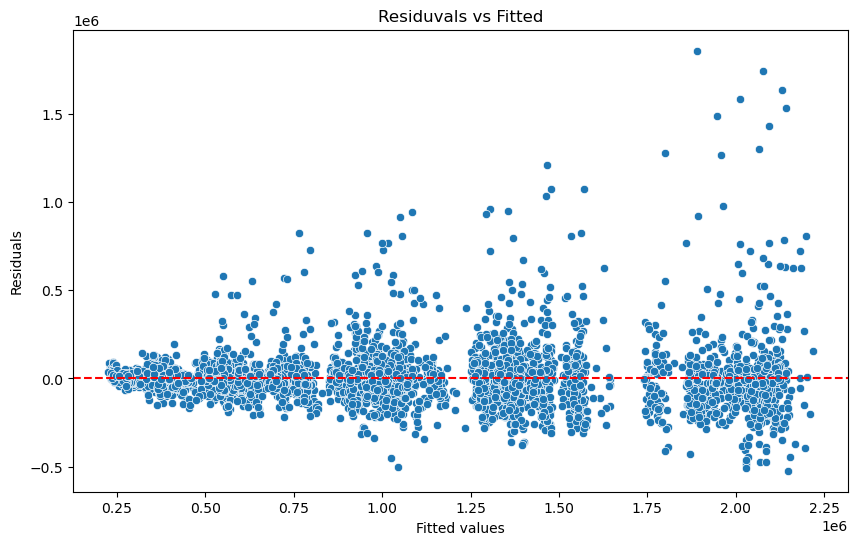

In [62]:
residuals1 = base_model1.resid
fitted_val1 = base_model1.fittedvalues

plt.figure(figsize=(10,6))
sns.scatterplot(x= fitted_val1, y = residuals1)
plt.axhline(y = 0, color = 'red', linestyle = '--')
plt.title('Residuvals vs Fitted')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()
          


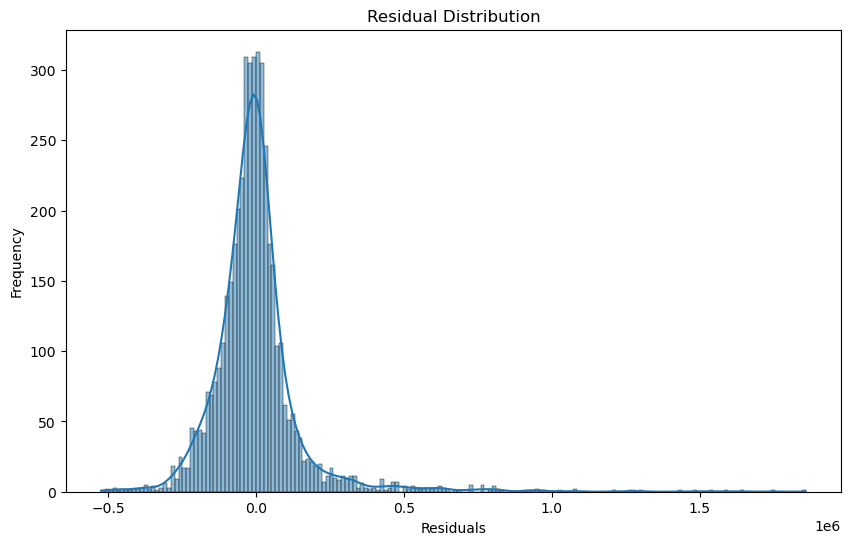

<Figure size 1000x600 with 0 Axes>

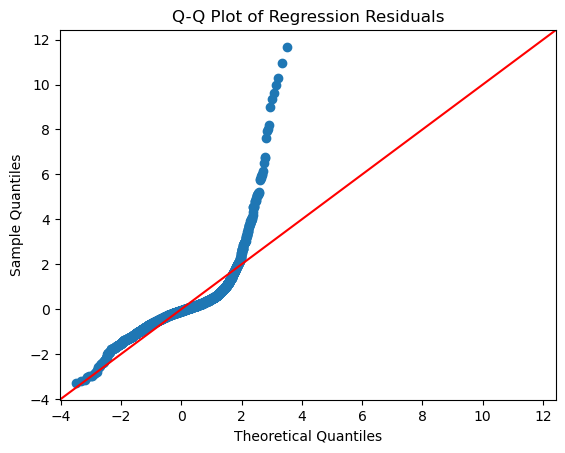

In [63]:
plt.figure(figsize=(10,6))
sns.histplot(data = residuals1, kde = True)
plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10,6))
sm.qqplot(data = residuals1, line ='45', fit = True)
plt.title('Q-Q Plot of Regression Residuals')
plt.show()

In [64]:
vif_data = pd.DataFrame()
vif_data['Feature'] = base_model1.model.exog_names
vif_data['VIF'] = [ variance_inflation_factor(base_model1.model.exog,i)
                   for i in range(base_model1.model.exog.shape[1])]
print(vif_data)

         Feature         VIF
0          const  499.557149
1   Holiday_Flag    1.038031
2    Temperature    1.464012
3     Fuel_Price    1.690340
4   Unemployment   13.367205
5        Store_2    1.945961
6        Store_3    2.027208
7        Store_4    2.222826
8        Store_5    2.026412
9        Store_6    2.079436
10       Store_7    2.139735
11       Store_8    2.160369
12       Store_9    2.113211
13      Store_10    1.981245
14      Store_11    2.017472
15      Store_12    4.873816
16      Store_13    1.931374
17      Store_14    2.054090
18      Store_15    2.094559
19      Store_16    2.050224
20      Store_17    2.056140
21      Store_18    2.228696
22      Store_19    1.963050
23      Store_20    1.982932
24      Store_21    1.825776
25      Store_22    2.005527
26      Store_23    2.453645
27      Store_24    2.139292
28      Store_25    1.995331
29      Store_26    1.990000
30      Store_27    1.951227
31      Store_28    4.825264
32      Store_29    2.545587
33      Store_

In [65]:
y_pred = base_model1.predict(x_test_sm)
y_pred_train = base_model1.predict(x_train_sm)

In [66]:
print('Train R2:', r2_score(y_train, y_pred_train))
print('Train MAE:', mean_absolute_error(y_train, y_pred_train))
print('Train MSE:', mean_squared_error(y_train, y_pred_train))

print('Test R2:', r2_score(y_test, y_pred))
print('Test MAE:', mean_absolute_error(y_test, y_pred))
print('Test MSE:', mean_squared_error(y_test, y_pred))

Train R2: 0.9201249792171914
Train MAE: 91445.72968746343
Train MSE: 25314993589.019512
Test R2: 0.9188571934088932
Test MAE: 91157.06000329422
Test MSE: 26127110251.269646


### Impact of Removing CPI
CPI was initially associated with a high VIF of approximately 414.69, indicating substantial multicollinearity. After removing CPI, VIF values for most Store dummy variables decreased considerably. Unemployment VIF also declined from 16.36 to 13.37.

Despite removing CPI, the model maintained comparable predictive performance, with test R² improving marginally from 0.91882 to 0.91886 and test MAE decreasing from approximately 91,581 to 91,157.

Based on these results, the model without CPI was selected as the preferred candidate for further validation. Its performance will be reassessed using a chronological train-test split.

In [67]:
comparison = pd.DataFrame({
    'Metric': ['Train R²', 'Test R²', 'Train MAE', 'Test MAE', 'Train MSE', 'Test MSE'],
    'Model 1 (With CPI)': [
        0.92028, 0.91882, 91678.97, 91581.27,
        25264738539.29, 26138847584.15
    ],
    'Model 2 (Without CPI)': [
        0.92012, 0.91886, 91445.73, 91157.06,
        25314993589.02, 26127110251.27
    ]
})

comparison

,Metric,Model 1 (With CPI),Model 2 (Without CPI)
0,Train R²,9.202800e-01,9.201200e-01
1,Test R²,9.188200e-01,9.188600e-01
2,Train MAE,9.167897e+04,9.144573e+04
3,Test MAE,9.158127e+04,9.115706e+04
4,Train MSE,2.526474e+10,2.531499e+10
5,Test MSE,2.613885e+10,2.612711e+10


In [7]:
import os
print(os.getcwd())

C:\Users\irshu
